In [1]:
!pip install poetry

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.6/307.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.6/413.6 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 464.5/464.5 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 70.4 MB/s eta 0:00:00


In [2]:
!poetry init


This command will guide you through creating your pyproject.toml config.

Package name [content]:  
Version [0.1.0]:  
Description []:  
Author [None, n to skip]:  n
License []:  
Compatible Python versions [>=3.13]:  

Would you like to define your main dependencies interactively? (yes/no) [yes] 
        You can specify a package in the following forms:
          - A single name (requests): this will search for matches on PyPI
          - A name and a constraint (requests@^2.23.0)
          - A git url (git+https://github.com/python-poetry/poetry.git)
          - A git url with a revision         (git+https://github.com/python-poetry/poetry.git#develop)
          - A file path (../my-package/my-package.whl)
          - A directory (../my-package/)
          - A url (https://example.com/packages/my-package-0.1.0.tar.gz)
        
Package to add or search for (leave blank to skip): 

Would you like to define your development dependencies interactively? (yes/no) [yes] 
Package to add or 

In [3]:
!pip install langchain langgraph langchain-tavily

In [4]:
!pip install -U "langchain-openrouter"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.3/837.3 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 463.6/463.6 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 56.8 MB/s eta 0:00:00
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.46.5
    Uninstalling pydantic_core-2.46.5:
      Successfully uninstalled pydantic_core-2.46.5
  Attempting uninstall: pydantic
    Found existing installation: pydantic 2.13.5
    Uninstalling pydantic-2.13.5:
      Successfully uninstalled pydantic-2.13.5


In [5]:
import os

os.environ["OPENROUTER_API_KEY"] = "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"
os.environ['TAVILY_API_KEY'] = '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'

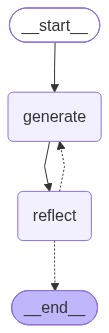


FINAL ANSWER:
RAG (Retrieval-Augmented Generation) is useful because it combines a large language model with an external knowledge source, allowing the model to retrieve relevant information before generating an answer. This improves accuracy, reduces hallucinations, and keeps responses grounded in verifiable, up-to-date data.

Key benefits:

- **Better accuracy**: The model bases answers on retrieved evidence, not just memorized patterns.
- **Reduced hallucinations**: It can cite or reference real sources, making outputs more reliable.
- **Current information**: External databases can be updated continuously, so the model can access recent events or private documents without retraining.
- **Domain customization**: Organizations can connect the model to their own knowledge bases, manuals, or databases to get specialized, relevant answers.
- **Cost efficiency**: Instead of fine-tuning expensive models, you can simply update the retrieval index.
- **Transparency and trust**: Users can c

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict

from langchain_openrouter import ChatOpenRouter
from langchain_core.messages import HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from IPython.display import Image, display


# ============================================================
# 1. STATE
# ============================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]


# ============================================================
# 2. LLM
# ============================================================

llm = ChatOpenRouter(
    model="auto"
)


# ============================================================
# 3. GENERATOR
# ============================================================

def generate(state: State):

    response = llm.invoke([
        *state["messages"],

        HumanMessage(
            content="""
            Generate the answer to the user's question.

            If previous reflection feedback exists,
            use it to improve the answer.

            Return ONLY the answer.
            """
        )
    ])

    return {
        "messages": [response]
    }


# ============================================================
# 4. REFLECTOR
# ============================================================

def reflect(state: State):

    response = llm.invoke([
        *state["messages"],

        HumanMessage(
            content="""
            Review the latest generated answer.

            Decide whether the answer is good enough.

            Your response MUST start with exactly one of:

            STOP
            CONTINUE

            Use STOP if the answer is good enough.

            Use CONTINUE if the answer should be improved.

            After STOP or CONTINUE, provide a short explanation
            and feedback for the generator.
            """
        )
    ])

    return {
        "messages": [response]
    }


# ============================================================
# 5. ITERATION CONTROL
# ============================================================

MAX_ITERATIONS = 3
iteration = 0


# ============================================================
# 6. SHOULD CONTINUE
# ============================================================

def should_continue(state: State):

    global iteration

    iteration += 1

    reflection = state["messages"][-1].content.strip().upper()

    # LLM says STOP
    if reflection.startswith("STOP"):
        return END

    # Maximum iterations reached
    if iteration >= MAX_ITERATIONS:
        return END

    # LLM says CONTINUE
    return "generate"


# ============================================================
# 7. BUILD GRAPH
# ============================================================

graph = StateGraph(State)

graph.add_node("generate", generate)
graph.add_node("reflect", reflect)

graph.add_edge(
    START,
    "generate"
)

graph.add_edge(
    "generate",
    "reflect"
)

graph.add_conditional_edges(
    "reflect",
    should_continue,
    {
        "generate": "generate",
        END: END
    }
)


# ============================================================
# 8. COMPILE
# ============================================================

app = graph.compile()


# ============================================================
# 9. PRINT GRAPH
# ============================================================

png = app.get_graph().draw_mermaid_png()

display(Image(png))


# ============================================================
# 10. RUN
# ============================================================

iteration = 0

result = app.invoke({
    "messages": [
        HumanMessage(
            content="Explain why RAG is useful."
        )
    ]
})


# ============================================================
# 11. PRINT FINAL ANSWER
# ============================================================

print("\nFINAL ANSWER:")
print(result["messages"][-2].content)

# **Final Code - Corrected with Structured Output**

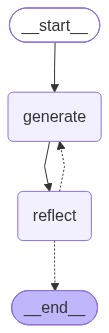


Reflection:
Decision: stop
Feedback: The previous answer clearly explains what RAG is and covers the main benefits: accuracy, reduced hallucinations, domain-specific grounding, cost-efficiency, transparency, and handling of niche queries. It is well-organized, easy to read, and directly answers the user's question. No further improvement is necessary.

FINAL ANSWER:
RAG (Retrieval-Augmented Generation) is useful because it combines the strengths of large language models with external knowledge sources. Instead of relying only on what the model learned during training, RAG retrieves relevant documents or data at generation time and uses them to ground the answer.

Key benefits:

- **More accurate and up-to-date answers** – RAG can pull from current databases, websites, or internal documents, so it doesn’t rely on stale or incomplete training data.
- **Reduces hallucinations** – By grounding responses in retrieved evidence, the model is less likely to invent facts or make things up.
- *

In [6]:
from typing import Annotated, Literal
from typing_extensions import TypedDict

from pydantic import BaseModel, Field

from langchain_openrouter import ChatOpenRouter
from langchain_core.messages import HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from IPython.display import Image, display


# ============================================================
# 1. STATE
# ============================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]
    decision: str


# ============================================================
# 2. LLM
# ============================================================

llm = ChatOpenRouter(
    model="auto"
)


# ============================================================
# 3. REFLECTION OUTPUT
# ============================================================

class ReflectionDecision(BaseModel):

    decision: Literal["continue", "stop"] = Field(
        description=(
            "Choose 'continue' if the answer needs improvement, "
            "or 'stop' if the answer is good enough."
        )
    )

    feedback: str = Field(
        description=(
            "Explain why the answer needs improvement or why "
            "it is good enough. If continuing, provide specific, "
            "actionable suggestions for improving the answer."
        )
    )


reflector_llm = llm.with_structured_output(
    ReflectionDecision
)


# ============================================================
# 4. GENERATOR
# ============================================================

def generate(state: State):

    response = llm.invoke([
        *state["messages"],

        HumanMessage(
            content="""
Generate an answer to the user's question.

If reflection feedback is available,
improve the previous answer using that feedback.

Return only the answer.
"""
        )
    ])

    return {
        "messages": [response]
    }


# ============================================================
# 5. REFLECTOR
# ============================================================

def reflect(state: State):

    response = reflector_llm.invoke([
        *state["messages"],

        HumanMessage(
            content="Review the latest generated answer and decide whether it needs improvement."
        )
    ])

    print("\nReflection:")
    print("Decision:", response.decision)
    print("Feedback:", response.feedback)

    return {
        "decision": response.decision,
        "messages": [
            HumanMessage(
                content=f"Reflection feedback: {response.feedback}"
            )
        ]
    }


# ============================================================
# 6. ITERATION LIMIT
# ============================================================

MAX_ITERATIONS = 3
iteration = 0


# ============================================================
# 7. SHOULD CONTINUE
# ============================================================

def should_continue(state: State):

    global iteration

    iteration += 1

    if state["decision"] == "stop":
        return END

    if iteration >= MAX_ITERATIONS:
        return END

    return "generate"


# ============================================================
# 8. BUILD GRAPH
# ============================================================

graph = StateGraph(State)

graph.add_node("generate", generate)
graph.add_node("reflect", reflect)

graph.add_edge(START, "generate")
graph.add_edge("generate", "reflect")

graph.add_conditional_edges(
    "reflect",
    should_continue,
    {
        "generate": "generate",
        END: END
    }
)


# ============================================================
# 9. COMPILE
# ============================================================

app = graph.compile()


# ============================================================
# 10. DISPLAY GRAPH
# ============================================================

png = app.get_graph().draw_mermaid_png()

display(Image(png))


# ============================================================
# 11. RUN
# ============================================================

iteration = 0

result = app.invoke({
    "messages": [
        HumanMessage(
            content="Explain why RAG is useful."
        )
    ],
    "decision": ""
})


# ============================================================
# 12. PRINT FINAL ANSWER
# ============================================================

for message in reversed(result["messages"]):

    if message.type == "ai":
        print("\nFINAL ANSWER:")
        print(message.content)
        break